In [8]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_diabetes

# Set up raw data
diabetes_raw = load_diabetes(as_frame=True)
working_df = diabetes_raw.frame

# Let's rename columns to be highly readable for our custom analysis
working_df.columns = ['Age', 'Sex', 'BMI', 'BP', 'S1', 'S2', 'S3', 'S4', 'S5', 'S6', 'Progression']

print(f"-> Loaded dataset shape: {working_df.shape}")
display(working_df.head(6))

-> Loaded dataset shape: (442, 11)


,Age,Sex,BMI,BP,S1,S2,S3,S4,S5,S6,Progression
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0
5,-0.092695,-0.044642,-0.040696,-0.019442,-0.068991,-0.079288,0.041277,-0.076395,-0.041176,-0.096346,97.0


In [9]:
# Data scrubbing validation
def check_dataset_integrity(dataframe):
    print("=== NULL VALUE AUDIT ===")
    nulls = dataframe.isna().sum()
    pct = (nulls / len(dataframe)) * 100
    report = pd.DataFrame({'Total Nulls': nulls, 'Pct (%)': pct.round(2)})
    display(report)

    dupes = dataframe.duplicated().sum()
    print(f"\nDetected duplicates count: {dupes}")

check_dataset_integrity(working_df)

=== NULL VALUE AUDIT ===


,Total Nulls,Pct (%)
Age,0,0.0
Sex,0,0.0
BMI,0,0.0
BP,0,0.0
S1,0,0.0
S2,0,0.0
S3,0,0.0
S4,0,0.0
S5,0,0.0
S6,0,0.0



Detected duplicates count: 0


In [10]:
# Basic analysis using NumPy structures
target_values = working_df['Progression'].to_numpy()
bmi_values = working_df['BMI'].to_numpy()

# Compute key target statistics with NumPy
stats_summary = {
    "Mean Value": np.mean(target_values),
    "Middle Point (Med)": np.median(target_values),
    "Dispersion (Std)": np.std(target_values),
    "Lowest": np.min(target_values),
    "Highest": np.max(target_values),
    "Q1 (25%)": np.percentile(target_values, 25),
    "Q3 (75%)": np.percentile(target_values, 75)
}

print("=== NUMPY STATISTICAL DASHBOARD ===")
for key, metric in stats_summary.items():
    print(f"{key:20s}: {metric:,.3f}")

# Feature scale calculation (Progression over BMI ratio)
bmi_to_progression_ratio = target_values / (bmi_values + 1.0) # avoid division by zero
print(f"\nCalculated Ratio Sample (first 5 values):\n", bmi_to_progression_ratio[:5])

=== NUMPY STATISTICAL DASHBOARD ===
Mean Value          : 152.133
Middle Point (Med)  : 140.500
Dispersion (Std)    : 77.006
Lowest              : 25.000
Highest             : 346.000
Q1 (25%)            : 87.000
Q3 (75%)            : 211.500

Calculated Ratio Sample (first 5 values):
 [142.22524209  79.07005695 134.99912509 208.41659342 140.09740081]


In [11]:
# Exploratory Data Analysis with Pandas API
print("=== PANDAS STATISTICAL SUMMARY ===")
display(working_df.describe().T)

print("\n=== CORRELATION COEFFICIENTS (PEARSON) ===")
corr_matrix = working_df.corr()
display(corr_matrix)

=== PANDAS STATISTICAL SUMMARY ===


,count,mean,std,min,25%,50%,75%,max
Age,442.0,-2.511817e-19,0.047619,-0.107226,-0.037299,0.005383,0.038076,0.110727
Sex,442.0,1.230790e-17,0.047619,-0.044642,-0.044642,-0.044642,0.050680,0.050680
BMI,442.0,-2.245564e-16,0.047619,-0.090275,-0.034229,-0.007284,0.031248,0.170555
BP,442.0,-4.797570e-17,0.047619,-0.112399,-0.036656,-0.005670,0.035644,0.132044
S1,442.0,-1.381499e-17,0.047619,-0.126781,-0.034248,-0.004321,0.028358,0.153914
S2,442.0,3.918434e-17,0.047619,-0.115613,-0.030358,-0.003819,0.029844,0.198788
S3,442.0,-5.777179e-18,0.047619,-0.102307,-0.035117,-0.006584,0.029312,0.181179
S4,442.0,-9.042540e-18,0.047619,-0.076395,-0.039493,-0.002592,0.034309,0.185234
S5,442.0,9.293722e-17,0.047619,-0.126097,-0.033246,-0.001947,0.032432,0.133597
S6,442.0,1.130318e-17,0.047619,-0.137767,-0.033179,-0.001078,0.027917,0.135612



=== CORRELATION COEFFICIENTS (PEARSON) ===


,Age,Sex,BMI,BP,S1,S2,S3,S4,S5,S6,Progression
Age,1.000000,0.173737,0.185085,0.335428,0.260061,0.219243,-0.075181,0.203841,0.270774,0.301731,0.187889
Sex,0.173737,1.000000,0.088161,0.241010,0.035277,0.142637,-0.379090,0.332115,0.149916,0.208133,0.043062
BMI,0.185085,0.088161,1.000000,0.395411,0.249777,0.261170,-0.366811,0.413807,0.446157,0.388680,0.586450
BP,0.335428,0.241010,0.395411,1.000000,0.242464,0.185548,-0.178762,0.257650,0.393480,0.390430,0.441482
S1,0.260061,0.035277,0.249777,0.242464,1.000000,0.896663,0.051519,0.542207,0.515503,0.325717,0.212022
S2,0.219243,0.142637,0.261170,0.185548,0.896663,1.000000,-0.196455,0.659817,0.318357,0.290600,0.174054
S3,-0.075181,-0.379090,-0.366811,-0.178762,0.051519,-0.196455,1.000000,-0.738493,-0.398577,-0.273697,-0.394789
S4,0.203841,0.332115,0.413807,0.257650,0.542207,0.659817,-0.738493,1.000000,0.617859,0.417212,0.430453
S5,0.270774,0.149916,0.446157,0.393480,0.515503,0.318357,-0.398577,0.617859,1.000000,0.464669,0.565883
S6,0.301731,0.208133,0.388680,0.390430,0.325717,0.290600,-0.273697,0.417212,0.464669,1.000000,0.382483


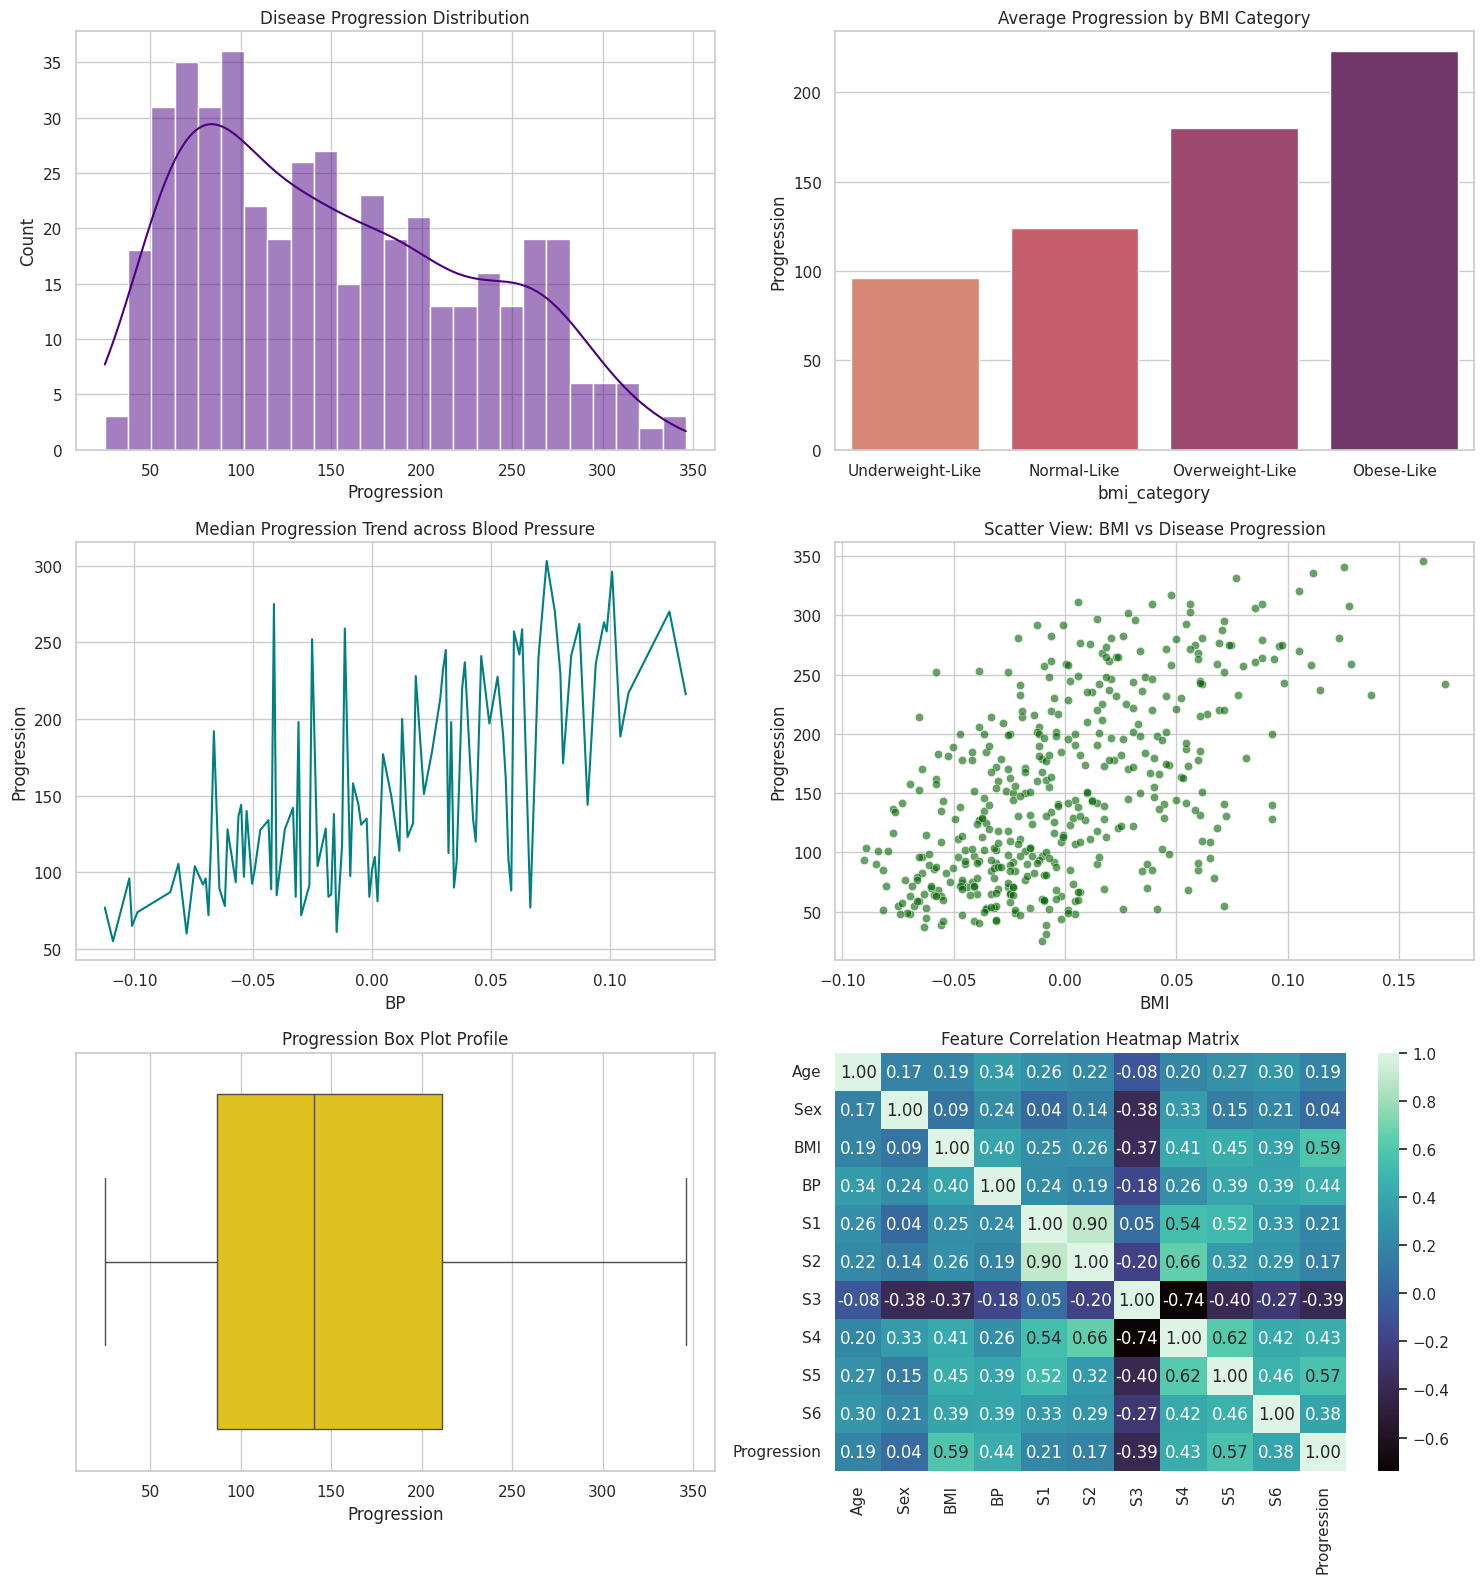

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configure custom visualization style
sns.set_theme(style="whitegrid", palette="muted")
fig, axes = plt.subplots(3, 2, figsize=(15, 16))

# 1. Progression Distribution
sns.histplot(working_df['Progression'], bins=25, kde=True, ax=axes[0, 0], color='indigo')
axes[0, 0].set_title('Disease Progression Distribution', fontsize=12)

# 2. BMI Binning Group Analysis
working_df['bmi_category'] = pd.cut(working_df['BMI'], bins=[-0.2, -0.05, 0.0, 0.05, 0.2], labels=['Underweight-Like', 'Normal-Like', 'Overweight-Like', 'Obese-Like'])
bmi_progression = working_df.groupby('bmi_category', observed=False)['Progression'].mean().reset_index()
sns.barplot(data=bmi_progression, x='bmi_category', y='Progression', ax=axes[0, 1], palette='flare', hue='bmi_category', legend=False)
axes[0, 1].set_title('Average Progression by BMI Category', fontsize=12)

# 3. BP vs Progression Trend
bp_progression = working_df.groupby('BP')['Progression'].median().reset_index()
sns.lineplot(data=bp_progression, x='BP', y='Progression', ax=axes[1, 0], color='teal', linewidth=1.5)
axes[1, 0].set_title('Median Progression Trend across Blood Pressure', fontsize=12)

# 4. BMI vs Progression Scatter Plot
sns.scatterplot(data=working_df, x='BMI', y='Progression', alpha=0.6, ax=axes[1, 1], color='darkgreen')
axes[1, 1].set_title('Scatter View: BMI vs Disease Progression', fontsize=12)

# 5. Outliers Analysis
sns.boxplot(x=working_df['Progression'], ax=axes[2, 0], color='gold')
axes[2, 0].set_title('Progression Box Plot Profile', fontsize=12)

# 6. Comprehensive Heatmap
sns.heatmap(working_df.corr(numeric_only=True), annot=True, cmap='mako', fmt='.2f', ax=axes[2, 1])
axes[2, 1].set_title('Feature Correlation Heatmap Matrix', fontsize=12)

plt.tight_layout()
plt.show()

In [13]:
import plotly.express as px

# 1. Interactive Histogram
fig1 = px.histogram(working_df, x='Progression', nbins=30, title='Interactive Distribution of Progression Metrics', color_discrete_sequence=['darkorchid'])
fig1.show()

# 2. Interactive Scatter
fig2 = px.scatter(working_df, x='BMI', y='Progression', color='BP', hover_data=['Age', 'Sex'], title='Interactive Mapping: BMI vs Progression (Sized by Blood Pressure)')
fig2.show()

# 3. Interactive Bar Chart
bmi_age_group = working_df.groupby('bmi_category', observed=False)['Age'].mean().reset_index()
fig3 = px.bar(bmi_age_group, x='bmi_category', y='Age', title='Interactive Plot: Mean Age Metric across BMI Categories', color='Age', color_continuous_scale='Sunset')
fig3.show()

In [14]:
from sklearn.preprocessing import RobustScaler

# Feature Generation Step
# 1. Ratio of S1 (total cholesterol) to S2 (low-density lipoproteins)
working_df['cholesterol_ratio'] = working_df['S1'] / (working_df['S2'] + 0.0001)

# 2. Overall serum measurement interaction feature
working_df['serum_interaction'] = working_df['S3'] * working_df['S4']

# 3. BP to BMI physical ratio
working_df['bp_bmi_ratio'] = working_df['BP'] / (working_df['BMI'] + 0.0001)

# Scaling engineered features via RobustScaler (handles outlier distributions elegantly)
robust_scaler = RobustScaler()
engineered_cols = ['cholesterol_ratio', 'serum_interaction', 'bp_bmi_ratio']
scaled_cols = ['scaled_chol_ratio', 'scaled_serum_interact', 'scaled_bp_bmi']

working_df[scaled_cols] = robust_scaler.fit_transform(working_df[engineered_cols])

print("=== COMPLETED ENGINEERED AND ROBUST SCALED FEATURES ===")
display(working_df[engineered_cols + scaled_cols].head(5))

=== COMPLETED ENGINEERED AND ROBUST SCALED FEATURES ===


,cholesterol_ratio,serum_interaction,bp_bmi_ratio,scaled_chol_ratio,scaled_serum_interact,scaled_bp_bmi
0,1.273690,0.000113,0.353944,0.410978,0.348314,-0.101056
1,0.443192,-0.002939,0.512467,-0.580876,-0.872923,-0.018380
2,1.337444,0.000084,-0.127279,0.487119,0.336855,-0.352033
3,0.485862,-0.001236,3.188868,-0.529915,-0.191574,1.377467
4,0.250689,-0.000021,-0.602799,-0.810780,0.294837,-0.600035
